# Preparing and visualizing pumpkin data

This notebook cleans the repository's pumpkin market data, normalizes fractional-bushel prices, and compares Matplotlib with Seaborn for regression-oriented exploration.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

## Load and clean the data

Prices from half-bushel and 1 1/9-bushel packages are divided by their package volume so every observation is expressed per bushel. Other bushel-labelled packages already represent one bushel.

In [2]:
data_path = Path("../../../2-Regression/data/US-pumpkins.csv")
assert data_path.is_file(), f"Missing dataset: {data_path.resolve()}"

raw_pumpkins = pd.read_csv(data_path)
columns = ["Date", "Package", "Low Price", "High Price", "City Name", "Variety"]
pumpkins = raw_pumpkins.loc[
    raw_pumpkins["Package"].str.contains("bushel", case=False, na=False), columns
].copy()
pumpkins["Date"] = pd.to_datetime(pumpkins["Date"], format="%m/%d/%y", errors="coerce")
for column in ("Low Price", "High Price"):
    pumpkins[column] = pd.to_numeric(pumpkins[column], errors="coerce")
pumpkins = pumpkins.dropna(subset=["Date", "Low Price", "High Price"]).copy()

pumpkins["Package Volume (bushels)"] = np.select(
    [
        pumpkins["Package"].str.contains("1 1/9", regex=False),
        pumpkins["Package"].str.contains("1/2", regex=False),
    ],
    [10 / 9, 1 / 2],
    default=1.0,
)
pumpkins["Quoted Price"] = (pumpkins["Low Price"] + pumpkins["High Price"]) / 2
pumpkins["Price per Bushel"] = pumpkins["Quoted Price"] / pumpkins["Package Volume (bushels)"]
pumpkins["Month"] = pumpkins["Date"].dt.month
pumpkins["Day of Year"] = pumpkins["Date"].dt.dayofyear

assert not pumpkins.empty
assert pd.api.types.is_numeric_dtype(pumpkins["Price per Bushel"])
assert np.isfinite(pumpkins["Price per Bushel"]).all()
assert pumpkins["Price per Bushel"].gt(0).all()
print(f"Clean bushel observations: {len(pumpkins)}")
pumpkins[["Date", "Package", "Month", "Price per Bushel"]].head()

Clean bushel observations: 415


,Date,Package,Month,Price per Bushel
70,2016-09-24,1 1/9 bushel cartons,9,13.5
71,2016-09-24,1 1/9 bushel cartons,9,16.2
72,2016-10-01,1 1/9 bushel cartons,10,16.2
73,2016-10-01,1 1/9 bushel cartons,10,15.3
74,2016-10-08,1 1/9 bushel cartons,10,13.5


## Matplotlib: relationship and distribution

The scatter plot preserves every observation, while the histogram makes the skew and high-price tail easier to see.

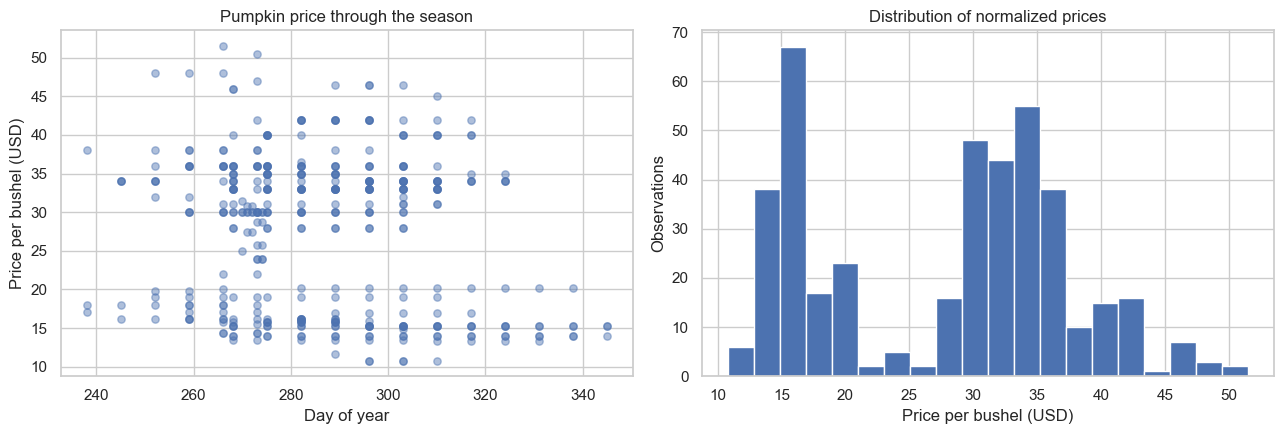

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(
    pumpkins["Day of Year"], pumpkins["Price per Bushel"], alpha=0.45, s=28
)
axes[0].set(
    title="Pumpkin price through the season",
    xlabel="Day of year",
    ylabel="Price per bushel (USD)",
)
axes[1].hist(pumpkins["Price per Bushel"], bins=20, edgecolor="white")
axes[1].set(
    title="Distribution of normalized prices",
    xlabel="Price per bushel (USD)",
    ylabel="Observations",
)
fig.tight_layout()
plt.show()

## Seaborn: regression and residual views

The fitted line summarizes a linear relationship, while the residual view checks whether that simple shape leaves systematic structure behind.

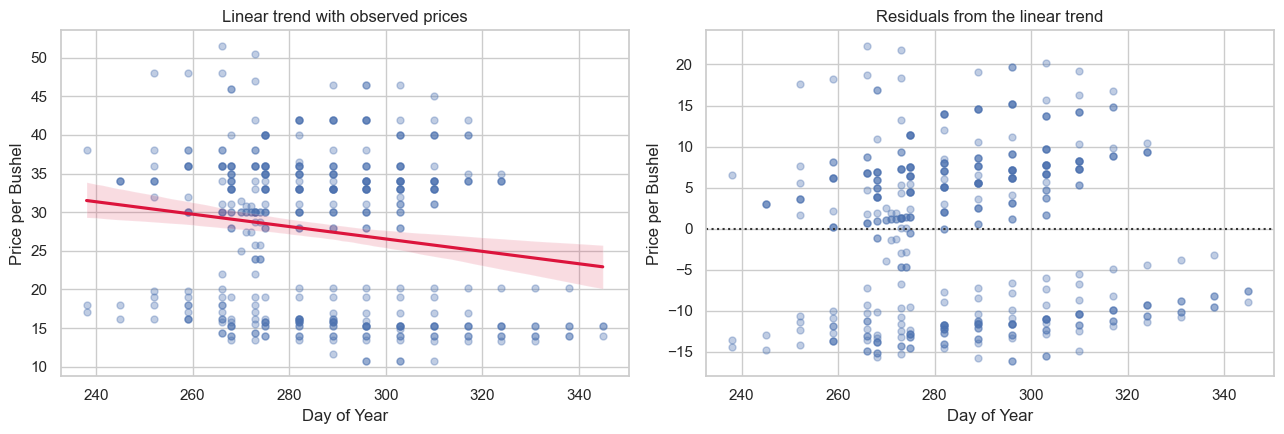

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(
    data=pumpkins, x="Day of Year", y="Price per Bushel",
    scatter_kws={"alpha": 0.35, "s": 25}, line_kws={"color": "crimson"}, ax=axes[0],
)
axes[0].set_title("Linear trend with observed prices")
sns.residplot(
    data=pumpkins, x="Day of Year", y="Price per Bushel",
    lowess=False, scatter_kws={"alpha": 0.35, "s": 25}, ax=axes[1],
)
axes[1].set_title("Residuals from the linear trend")
fig.tight_layout()
plt.show()

## Seaborn: categorical comparison and correlations

Monthly box plots retain within-month spread that a chart of monthly means would hide. The heatmap is a compact screen for linear association, not proof of causation or model accuracy.

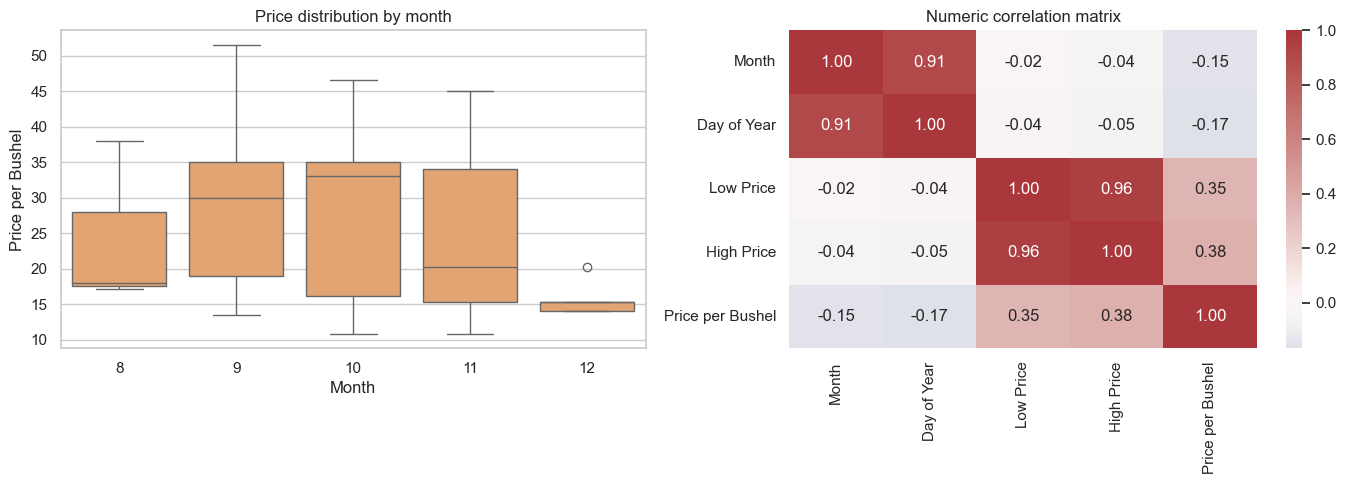

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=pumpkins, x="Month", y="Price per Bushel", color="#f4a261", ax=axes[0])
axes[0].set_title("Price distribution by month")
numeric_columns = [
    "Month", "Day of Year", "Low Price", "High Price", "Price per Bushel"
]
correlations = pumpkins[numeric_columns].corr()
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Numeric correlation matrix")
fig.tight_layout()
plt.show()

## Findings

The normalized prices are right-skewed and vary substantially within the same month. The fitted straight line gives only a rough seasonal summary; the scatter and residual plots show why a single linear relationship should not be accepted from correlation alone. Seaborn makes these statistical comparisons concise, while Matplotlib gives direct control over every visual element.